In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from einops import rearrange
from tqdm import trange

# Import from the new package
from neural_me.physics.milne_eddington import MilneEddington
from neural_me.physics.zeeman import paramLine
from neural_me.utils.misc import regu, regu2, regu_value

print("Imports successful!")

Imports successful!


In [2]:
# Data Loading (Same as legacy)
skip_factor = 100
skip_wave = 16
fullpath = '/mn/stornext/d20/RoCS/carlosjd/projects/SUNTORCH/data/sunspot_SST/'
wl = np.load(fullpath+'observed_wave.npy')[:skip_wave] - 6301.51143134
dd = np.load(fullpath+'observed_stokes.npy')[:,:skip_wave,0::skip_factor, 0::skip_factor]

dd = rearrange(dd, 'ns nw ny nx -> ny nx ns nw')
ny, nx, ns, nw = dd.shape
print(f"Data shape: {dd.shape}")

Data shape: (10, 10, 4, 16)


In [3]:
# Model Wrapper for Optimization (Mimics ME_model in legacy)
class ME_model_Wrapper(nn.Module):
    def __init__(self, wl, dd, nlinea, mask=None):
        super().__init__()
        self.data = torch.from_numpy(np.array(dd.astype(np.float32)))
        self.wl = torch.from_numpy(np.array(wl.astype(np.float32)))
        self.me_physics = MilneEddington(nlinea)
        
        if mask is None: mask = range(self.data.shape[-1])
        self.mask = mask

        self.ny, self.nx, self.ns, self.nw = self.data.shape

        self.data_stokesI = self.data[:,:,0,:].reshape(self.ny*self.nx, self.nw)
        self.data_stokesQ = self.data[:,:,1,:].reshape(self.ny*self.nx, self.nw)
        self.data_stokesU = self.data[:,:,2,:].reshape(self.ny*self.nx, self.nw)
        self.data_stokesV = self.data[:,:,3,:].reshape(self.ny*self.nx, self.nw)

    def forward(self, params):
        # Pass flattened wavelengths
        wl_batch = self.wl.unsqueeze(0).repeat(params.shape[0], 1)
        return self.me_physics.forward(params, wl_batch)

    def evaluate(self, params, weights=[1.0, 1.0, 1.0, 1.0]):
        stokesI, stokesQ, stokesU, stokesV = self.forward(params)

        return weights[0]*torch.mean(torch.abs(self.data_stokesI - stokesI)[:, self.mask]) + \
               weights[1]*torch.mean(torch.abs(self.data_stokesQ - stokesQ)[:, self.mask]) + \
               weights[2]*torch.mean(torch.abs(self.data_stokesU - stokesU)[:, self.mask]) + \
               weights[3]*torch.mean(torch.abs(self.data_stokesV - stokesV)[:, self.mask])

mymodel = ME_model_Wrapper(wl, dd, nlinea=1)

----------------------------------------------------
Element = FE1
lambda0 = 6301.5012
ju=2.0, lu=2, su=2.0
jl=2.0, ll=1, sl=2.0
g_u  = 1.50
g_l  = 1.83
geff = 1.67


In [4]:
# Optimization Loop (Same as legacy)
def optimization(optimizer, niterations, parameters, model):
    img = model.data[:,:,0][None,:,:]
    t = trange(niterations, leave=True)
    
    for loop in t:
        optimizer.zero_grad()
        chi2loss = model.evaluate(parameters)
        
        # Regularization (disabled in legacy example, kept 0 here)
        reguloss = 0 * chi2loss
        loss = chi2loss + reguloss

        loss.backward()
        optimizer.step()
        t.set_postfix({'loss': loss.item(), 'chi2loss': chi2loss.item(), 'reguloss': reguloss.item()})

    outplot = parameters.detach().numpy().reshape(model.ny, model.nx, parameters.shape[-1])
    
    phiB = outplot[:,:,2]
    phiB[phiB < 0] += (np.pi)
    phiB[phiB > (np.pi)] -= (np.pi)
    outplot[:,:,2] = phiB
    outplot[:,:,0] = np.abs(outplot[:,:,0])
    
    return outplot

niter = 1000
out = torch.ones(dd.shape[0]*dd.shape[1], 9)
# Initial Guesses
out[:,0] = 0.5; out[:,1] = 1.0; out[:,2] = 1.0; out[:,3] = 0.0
out[:,4] = 50.0; out[:,5] = 0.2; out[:,6] = 0.02; out[:,7] = 0.5; out[:,8] = 0.5
out.requires_grad = True

optimizer = torch.optim.Adam([out], lr=5e-3)
outplot = optimization(optimizer=optimizer, niterations=niter, parameters=out, model=mymodel)

100%|██████████| 1000/1000 [00:12<00:00, 78.12it/s, loss=0.0165, chi2loss=0.0165, reguloss=0]


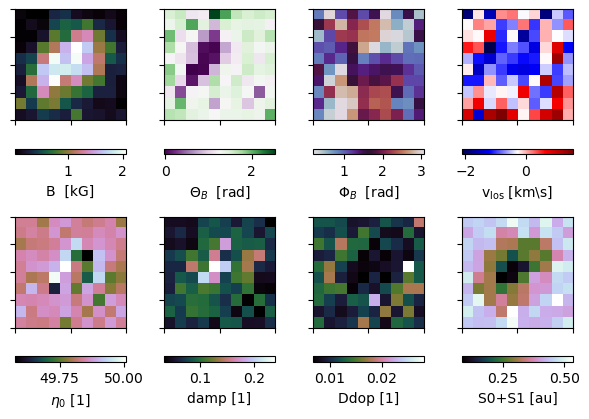

In [5]:
# Plot Results (Matches legacy plot)
name = 'baseline_verification_plot'
plt.close("all")
extent = np.float64((0, nx, 0, ny))
f, ax = plt.subplots(nrows=2, ncols=4, figsize=(9*2/3., 4.5))
axf = ax.flatten()

names = [r'B  [kG]', r'$\Theta_B$  [rad]', r'$\Phi_B$  [rad]',r'v$_{\rm los}$ [km\s]',
         r'$\eta_0$ [1]',r'damp [1]',r'Ddop [1]',r'S0+S1 [au]']
cmap_array = ['cubehelix','PRGn','twilight','seismic','cubehelix','cubehelix','cubehelix','cubehelix']

for i in range(8):
    im = axf[i].imshow(outplot[:,:,i], cmap=cmap_array[i], interpolation='nearest', extent=extent, origin='lower')
    f.colorbar(im, ax=axf[i], orientation='horizontal', label=names[i])
    axf[i].set_yticklabels([]); axf[i].set_xticklabels([])

f.set_tight_layout(True)
plt.savefig(name+'.pdf', bbox_inches='tight')
plt.show()